# Sparse attention kernel latency

Bar labels show Quest-FI latency divided by each method’s latency (speedup over Quest-FI).


In [1]:
%matplotlib inline
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.legend_handler import HandlerPatch
from matplotlib.patches import Rectangle
import numpy as np
from IPython.display import display

TEAL, BLUE, ORANGE, GRAY, INK = "#008b87", "#4f7192", "#c76524", "#737b81", "#243136"

def setup_style():
    plt.rcParams["hatch.linewidth"] = 0.5
    for name in ("Times New Roman.ttf", "Times New Roman Bold.ttf", "Times New Roman Italic.ttf"):
        path = Path("/System/Library/Fonts/Supplemental") / name
        if path.exists():
            font_manager.fontManager.addfont(str(path))
    plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"], "font.size": 8.5, "axes.labelsize": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.linewidth": .6, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK, "savefig.facecolor": "white"})

def axis_style(ax, grid_axis="both"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(width=.6, length=2, pad=2)
    ax.grid(axis=grid_axis, color="#dce2e5", linewidth=.45, zorder=0)
    ax.set_axisbelow(True)

setup_style()

In [12]:
# per-head FI/ group FI
# | Context | Batch | Quest 8% | + Twilight | + GAS | Less-style 8% |
# |---|---:|---:|---:|---:|---:|
# | 16K | 32 | 152.76 / 186.92 | 95.36 / 115.22 | 95.34 / 114.86 | 153.39 / 116.34 |
# | 16K | 64 | 285.50 / 295.90 | 94.42 / 115.09 | 94.50 / 114.34 | 286.12 / 174.62 |
# | 16K | 96 | 430.58 / 412.67 | 98.39 / 122.18 | 97.95 / 116.68 | 429.49 / 242.67 |
# | 16K | 128 | 578.72 / 538.05 | 104.64 / 132.95 | 99.16 / 116.19 | 582.47 / 311.65 |
# | 32K* | 32 | 303.07 / 367.51 | 97.94 / 124.64 | 99.26 / 118.79 | 305.92 / 211.34 |
# | 32K* | 64 | 636.26 / 593.90 | 106.16 / 139.19 | 100.83 / 117.87 | 596.03 / 343.09 |
# | 32K* | 96 | 1037.28 / 838.58 | 123.73 / 158.85 | 108.12 / 120.27 | 920.41 / 461.57 |
# | 32K* | 128 | 1454.91 / 1121.45 | 142.72 / 183.08 | 113.00 / 121.70 | 1250.39 / 594.16 |

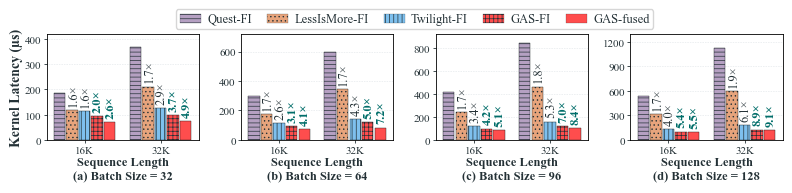

In [2]:
# Latencies in microseconds; rows: B32, B64, B96, B128; columns: 16K, 32K.
# Values and styles copied from the current fig6_kernel_Speedup.ipynb.
KERNEL_BATCHES = (32, 64, 96, 128)
KERNEL_LENGTHS = (16384, 32768)
KERNEL_LATENCY_US = {
    # 8192
    # 'quest': np.array([
    #     [857.93, 1035.60],  # B32
    #     [1345.55, 1851.60],  # B64
    #     [1566.16, 2108.05],  # B96
    #     [1848.74, 2374.68],  # B128
    # ]),
    # 'lessismore': np.array([
    #     [578.36, 578.32],  # B32
    #     [893.75, 892.42],  # B64
    #     [1226.92, 1234.01],  # B96
    #     [573.809067, 1567.75],  # B128
    # ]),
    # 'quest_twi': np.array([
    #     [144.58, 150.10],  # B32
    #     [194.22, 197.52],  # B64
    #     [234.76, 250.72],  # B96
    #     [282.27, 291.24],  # B128
    # ]),
    # 'gas': np.array([
    #     [118.07, 118.42],  # B32
    #     [126.81, 141.57],  # B64
    #     [167.05, 181.70],  # B96
    #     [201.29, 220.73],  # B128
    # ]),
    # 8% sparsity baseline
    'quest': np.array([
        [186.92, 367.51],  # B32
        [295.90, 593.90],  # B64
        [412.67, 838.58],  # B96
        [538.05, 1121.45],  # B128
    ]),
    'lessismore': np.array([
        [116.34, 211.34],  # B32
        [174.62, 343.09],  # B64
        [242.67, 461.57],  # B96
        [311.65, 594.16],  # B128
    ]),
    'quest_twi': np.array([
        [115.22, 124.64],  # B32
        [115.09, 139.19],  # B64
        [122.18, 158.85],  # B96
        [132.95, 183.08],  # B128
    ]),
    'gas': np.array([
        [95.34, 99.26],  # B32
        [94.50, 117.87],  # B64
        [97.95 , 120.27],  # B96
        [99.16, 126.35],  # B128
    ]),
    'gas_custom_us': np.array([
        [71.08,  75.47],   # B32:  16K, 32K
        [72.07,  82.64],   # B64
        [81.19,  99.89],   # B96
        [97.09, 123.21],   # B128
    ]),
}

KERNEL_STYLES = [('quest', 'Quest-FI', '#B5A0C2', '----'),
                 ('lessismore', 'LessIsMore-FI', '#E7A47C', '....'),
                 ('quest_twi', 'Twilight-FI', '#7EC0EE', '||||'),
                 ('gas', 'GAS-FI', '#FF4D4D', '++++'),
                 ('gas_custom_us', 'GAS-fused', '#FF4D4D', '')]


class LoweredLegendPatch(HandlerPatch):
    """Lower legend color swatches slightly to align visually with the text."""
    def create_artists(self, legend, orig_handle, xdescent, ydescent,
                       width, height, fontsize, trans):
        artists = super().create_artists(legend, orig_handle, xdescent, ydescent,
                                         width, height, fontsize, trans)
        for artist in artists:
            artist.set_y(artist.get_y() - 0.8)  # points; increase to lower further
        return artists


def sparse_kernel_figure(latency_us):
    """Plot sparse kernel latency; labels show Quest latency / method latency."""
    values = {method: np.asarray(latency_us[method], dtype=float)
              for method, *_ in KERNEL_STYLES}
    assert all(v.shape == (len(KERNEL_BATCHES), len(KERNEL_LENGTHS)) for v in values.values())
    fig, axes = plt.subplots(1, len(KERNEL_BATCHES), figsize=(8, 2))
    fig.subplots_adjust(left=.075, right=.995, top=.80, bottom=.27, wspace=.28)
    centers, width = np.arange(len(KERNEL_LENGTHS)), .825 / len(KERNEL_STYLES)
    limits = {32: (420, 100), 64: (720, 200), 96: (920, 200), 128: (1300, 300)}
    handles = []
    for panel, (ax, batch) in enumerate(zip(axes, KERNEL_BATCHES)):
        upper, step = limits[batch]
        axis_style(ax, "y")
        for spine in ax.spines.values():
            spine.set_visible(True)
        ax.grid(axis="y", color="#D3D9DE", linewidth=.45, linestyle=":")
        for j, (method, label, color, hatch) in enumerate(KERNEL_STYLES):
            xpos = centers + (j - (len(KERNEL_STYLES)-1)/2)*width
            bars = ax.bar(xpos, values[method][panel], width=width*.91, color=color,
                          hatch=hatch, edgecolor=INK, linewidth=.15, zorder=3)
            ax.bar(xpos, values[method][panel], width=width*.91, facecolor="none",
                   edgecolor="black", linewidth=.15, zorder=4)
            if panel == 0:
                handles.append(bars[0])
            if method != "quest":
                for k, rect in enumerate(bars):
                    ratio = values["quest"][panel, k] / values[method][panel, k]
                    ax.annotate(f"{ratio:.1f}×",
                                xy=(rect.get_x() + rect.get_width()/2, rect.get_height()),
                                xytext=(1, 3), textcoords="offset points", rotation=90,
                                ha="center", va="bottom", fontsize=9,
                                color="#006D69" if method in ("gas", "gas_custom_us") else INK,
                                weight="bold" if method in ("gas", "gas_custom_us") else "normal")
        ax.set(xlim=(-.5, 1.5), ylim=(0, upper), xticks=centers,
               xticklabels=[f"{n//1024}K" for n in KERNEL_LENGTHS],
               yticks=np.arange(0, upper, step))
        ax.tick_params(axis="y", labelsize=8, pad=2)
        ax.tick_params(axis="x", labelsize=8, pad=2)
        ax.set_xlabel("Sequence Length", labelpad=1,
                      fontdict={"size": 9, "weight": "bold", "fontfamily": "Times New Roman"})
        ax.annotate(f"({chr(97+panel)}) Batch Size = {batch}",
                    xy=(.5, 0), xycoords="axes fraction", xytext=(0, -23),
                    textcoords="offset points", ha="center", va="top",
                    fontsize=9, weight="bold", annotation_clip=False)
    axes[0].set_ylabel("Kernel Latency (µs)", labelpad=1,
                       fontdict={"size": 10, "weight": "bold", "fontfamily": "Times New Roman"})
    fig.legend(handles, [entry[1] for entry in KERNEL_STYLES],
               loc="upper center", bbox_to_anchor=(.535, .955), ncol=len(KERNEL_STYLES),
               frameon=True, fontsize=9, columnspacing=1.2,
               handlelength=1.7, handletextpad=.5, borderpad=.3, handleheight=.7,
               handler_map={Rectangle: LoweredLegendPatch()})
    return fig


if "fig_kernel" in globals():
    plt.close(fig_kernel)
fig_kernel = sparse_kernel_figure(KERNEL_LATENCY_US)
fig_kernel.savefig("sparse_attention_kernel.pdf", bbox_inches="tight")
plt.show()
plt.close(fig_kernel)


In [3]:
# Ratio > 1 means GAS-FI has lower kernel latency than the compared method.
gas_us = KERNEL_LATENCY_US["gas"]

for method, label, *_ in KERNEL_STYLES:
    if method != "gas":
        ratios = KERNEL_LATENCY_US[method] / gas_us
        print(
            f"GAS-FI vs {label}: "
            f"{ratios.min():.2f}× – {ratios.max():.2f}×"
        )

GAS-FI vs Quest-FI: 1.96× – 8.88×
GAS-FI vs LessIsMore-FI: 1.22× – 4.70×
GAS-FI vs Twilight-FI: 1.18× – 1.45×
GAS-FI vs GAS-fused: 0.70× – 0.98×


In [5]:
# Ratio > 1 means GAS-FI has lower kernel latency than the compared method.
gas_us = KERNEL_LATENCY_US["gas_custom_us"]

for method, label, *_ in KERNEL_STYLES:
    if method != "gas_custom_us":
        ratios = KERNEL_LATENCY_US[method] / gas_us
        print(
            f"GAS-fused vs {label}: "
            f"{ratios.min():.2f}× – {ratios.max():.2f}×"
        )

GAS-fused vs Quest-FI: 2.63× – 9.10×
GAS-fused vs LessIsMore-FI: 1.64× – 4.82×
GAS-fused vs Twilight-FI: 1.37× – 1.68×
GAS-fused vs GAS-FI: 1.02× – 1.43×
